# 05 — Paired significance and regional sample sizes

Analysis of the saved final experiment. Notebook numbering follows the requested presentation order; to generate the model comparison from scratch, run the single pipeline command first; then read these notebooks as reports. Historical Historical baseline results remain preserved.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display
PROJECT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'recommender').is_dir()), None)
assert PROJECT is not None, 'Open within the project folder'
import os
RESULTS = Path(os.environ.get('RESULTS_DIR', str(PROJECT / 'results/final'))).resolve()


In [2]:
assert (RESULTS / 'significance.csv').exists(), 'Run the pipeline first.'
display(json.loads((RESULTS / 'analysis_protocol.json').read_text()))


{'primary': 'paired permutation test on applicant-level grouped Recall@10 differences versus same-run M8',
 'paired_bootstrap_resamples': 10000,
 'seed': 42,
 'multiple_comparisons': 'Holm adjustment across models within each strict/grouped family',
 'regional_analysis': 'Descriptive; fewer than 20 test applicants flagged. Counts use applicant region for applications and vacancy region for job counts.',
 'selected_model': 'M8',
 'limitations': 'Observed invitation groups are incomplete relevance labels; historical test set has been inspected previously. No temporal or causal guarantee.'}

## Significance

The primary metric is applicant-level grouped Recall@10. Compare each model with the contemporaneous M8 using a paired permutation test and a paired bootstrap 95% interval (10,000 resamples, seed 42). Holm-adjust permutation p-values within the grouped comparison family; strict results are a separate family. Small p-values do not establish practical importance, causality or performance on future jobs.


In [3]:
significance = pd.read_csv(RESULTS / 'significance.csv')
display(significance[significance['mode'] == 'grouped'])
display(significance[significance['mode'] == 'strict'])


,model,reference,mode,metric,applicants,mean_difference,ci95_lower,ci95_upper,paired_permutation_p,improved,worse,holm_adjusted_permutation_p
0,M9 without region,M8,grouped,Recall@10,2806,-0.334818,-0.352923,-0.316749,0.000100,27,984,0.000600
2,M9 + region,M8,grouped,Recall@10,2806,-0.001960,-0.004811,0.000713,0.211979,5,11,0.847915
4,Logistic Regression,M8,grouped,Recall@10,2806,-0.000416,-0.006415,0.005585,0.906409,38,39,1.000000
6,Random Forest,M8,grouped,Recall@10,2806,-0.001069,-0.007310,0.005172,0.776222,40,43,1.000000
8,XGBoost,M8,grouped,Recall@10,2806,-0.000059,-0.006593,0.006534,1.000000,44,44,1.000000
10,M5,M8,grouped,Recall@10,2806,-0.010228,-0.017997,-0.002635,0.009499,47,78,0.047495


,model,reference,mode,metric,applicants,mean_difference,ci95_lower,ci95_upper,paired_permutation_p,improved,worse,holm_adjusted_permutation_p
1,M9 without region,M8,strict,Recall@10,2806,-0.230492,-0.246169,-0.214490,0.000100,19,680,0.000600
3,M9 + region,M8,strict,Recall@10,2806,-0.001307,-0.004574,0.001901,0.465853,10,14,0.544546
5,Logistic Regression,M8,strict,Recall@10,2806,0.009313,0.002554,0.016037,0.007999,65,40,0.039996
7,Random Forest,M8,strict,Recall@10,2806,0.005227,-0.004182,0.014433,0.272273,103,89,0.544546
9,XGBoost,M8,strict,Recall@10,2806,0.009343,0.000136,0.018460,0.045395,107,83,0.136186
11,M5,M8,strict,Recall@10,2806,-0.008719,-0.015253,-0.002049,0.011799,36,60,0.047195


## Number of applicants, vacancies and applications per region

Applicant-region counts and vacancy-region counts use their respective entities; they are not interchangeable. Eligible train/development/test counts cover applicants with at least one invitation. Regional performance is descriptive; fewer than 20 test applicants is flagged.


,region,applicants,vacancies,applications,positive_applications,training_applicants,development_applicants,test_applicants,invitation_rate
0,пермский край,9288,3773,16343,1958,1290,133,375,0.119807
1,санкт петербург,8430,3890,11438,2444,1623,167,430,0.213674
2,свердловская область,3621,2287,4761,705,473,54,144,0.148078
3,челябинская область,3522,2372,6480,583,397,38,108,0.089969
4,воронежская область,2383,931,3167,435,285,30,91,0.137354
...,...,...,...,...,...,...,...,...,...
106,республика ингушетия,0,1,0,0,0,0,0,NaN
107,республика калмыкия,0,21,0,0,0,0,0,NaN
108,республика татарстан (татарстан),0,321,0,0,0,0,0,NaN
109,республика карелия,0,149,0,0,0,0,0,NaN


<Axes: title={'center': 'Eligible applicants in the 20 largest applicant regions'}, ylabel='region'>

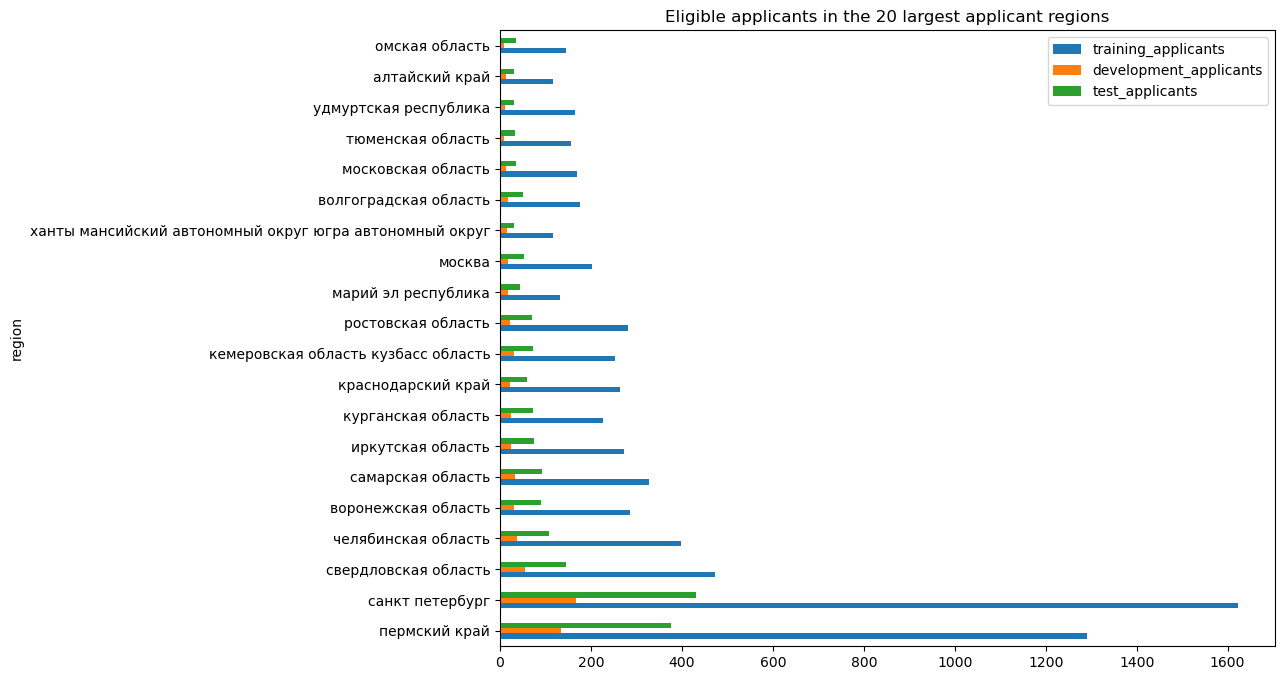

In [4]:
counts = pd.read_csv(RESULTS / 'region_counts.csv')
display(counts)
counts.set_index('region')[['training_applicants', 'development_applicants', 'test_applicants']].head(20).plot.barh(figsize=(10, 8), title='Eligible applicants in the 20 largest applicant regions')


In [5]:
regional = pd.read_csv(RESULTS / 'metrics_by_region.csv')
selected = json.loads((RESULTS / 'selection.json').read_text())['selected_model']
display(regional[regional.model.isin(['M8', selected])])


,region,test_applicants,model,grouped_Recall@10,grouped_NDCG@10,small_sample
0,алтай республика,1,M8,1.000000,0.630930,True
7,алтайский край,30,M8,0.500000,0.360708,False
14,амурская область,8,M8,0.750000,0.534213,True
21,архангельская область,14,M8,0.357143,0.188584,True
28,астраханская область,12,M8,0.666667,0.422087,True
...,...,...,...,...,...,...
560,чеченская республика,1,M8,1.000000,0.430677,True
567,чувашская республика чувашия,29,M8,0.586207,0.439354,False
574,чукотский автономный округ,1,M8,0.000000,0.000000,True
581,ямало ненецкий автономный округ,6,M8,0.500000,0.500000,True
